<a href="https://colab.research.google.com/github/germfsip/Inteligencia-Artificial-y-Machine-Learning-para-organizaciones/blob/main/UNIR_AA_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clase 2 · Evaluación de modelos de aprendizaje automático
**Inteligencia Artificial y Aprendizaje Automático para las Organizaciones · UNIR México**

Continuamos con la aseguradora de la Clase 1. Ya sabemos *plantear* un modelo; ahora vamos a responder la pregunta que hará cualquier directivo: **¿cómo sabemos que funciona?**

**Qué vas a hacer (40 a 50 minutos):**

| Parte | Pregunta | Tema 2 |
|---|---|---|
| A | ¿El modelo aprendió o memorizó? | Entrenamiento y prueba |
| B | ¿Cuánto confío en ese número? | Validación simple, k-fold y estratificada |
| C | ¿Cuánto se equivoca al estimar el costo de un siniestro? | SSE, MSE, RMSE, R², MAE, MAPE |
| D | ¿Cómo se equivoca al predecir cancelaciones? | Matriz de confusión, precisión, sensibilidad, F1, ROC, AUC y umbral |

**Cómo usarlo:** ejecuta las celdas en orden (Shift + Enter). No necesitas saber programar: lee, ejecuta y observa. Al final hay **tres retos breves** y un **anexo** con el código del manual corregido.

> Los datos son sintéticos y se generan dentro del cuaderno: no hay que descargar nada.

## 0 · Preparación: generamos la cartera de la aseguradora

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, ConfusionMatrixDisplay)

rng = np.random.default_rng(2026)
n = 3000
edad = rng.integers(20, 75, n)
antiguedad = rng.gamma(2.0, 18, n).round().clip(1, 180)
prima = (650 + 9 * edad + rng.normal(0, 180, n)).round(0)
reclamaciones = rng.poisson(0.6, n)
satisfaccion = rng.integers(1, 6, n)
digital = rng.binomial(1, 0.45, n)

# Cancelación (clasificación): ~17 % de la cartera
z = -2.2 - 0.035 * antiguedad + 1.1 * reclamaciones - 0.9 * (satisfaccion - 3) + 0.002 * (prima - 1000) + 0.6 * digital
cancela = rng.binomial(1, 1 / (1 + np.exp(-z)))

# Costo del último siniestro en miles de pesos (regresión)
costo = (8 + 0.12 * edad + 4.5 * reclamaciones + 0.004 * prima + rng.normal(0, 3, n)).clip(1)

df = pd.DataFrame({"edad": edad, "antiguedad_meses": antiguedad, "prima_mensual": prima,
                   "num_reclamaciones": reclamaciones, "satisfaccion": satisfaccion, "canal_digital": digital,
                   "costo_siniestro_miles": costo.round(2), "cancela": cancela})
print(df.shape)
print(f"Tasa de cancelación: {df.cancela.mean():.1%}")
df.head()

(3000, 8)
Tasa de cancelación: 16.8%


,edad,antiguedad_meses,prima_mensual,num_reclamaciones,satisfaccion,canal_digital,costo_siniestro_miles,cancela
0,66,6.0,1317.0,0,1,1,20.73,1
1,29,89.0,994.0,0,3,1,13.76,0
2,21,10.0,727.0,0,1,1,17.37,0
3,55,50.0,1089.0,0,5,0,21.48,0
4,40,24.0,1338.0,1,2,0,24.34,0


## Parte A · ¿Aprendió o memorizó?

Separamos 80 % para entrenar y 20 % para probar. Usamos `stratify=y` para que ambos conjuntos tengan la misma proporción de cancelaciones.

Después entrenamos un **árbol de decisión sin límite de profundidad**: un modelo capaz de memorizar cada cliente.

In [2]:
X = df[['edad','antiguedad_meses','prima_mensual','num_reclamaciones','satisfaccion','canal_digital']]
y = df["cancela"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
print(f"Entrenamiento: {len(X_train)} clientes · cancelación {y_train.mean():.1%}")
print(f"Prueba:        {len(X_test)} clientes · cancelación {y_test.mean():.1%}")

arbol = DecisionTreeClassifier(random_state=1).fit(X_train, y_train)
print(f"\nExactitud en entrenamiento: {accuracy_score(y_train, arbol.predict(X_train)):.1%}")
print(f"Exactitud en prueba:        {accuracy_score(y_test, arbol.predict(X_test)):.1%}")

Entrenamiento: 2400 clientes · cancelación 16.8%
Prueba:        600 clientes · cancelación 16.8%

Exactitud en entrenamiento: 100.0%
Exactitud en prueba:        75.7%


**Observa:** en entrenamiento el árbol acierta prácticamente todo; en prueba, bastante menos. Eso es **memorizar**: el estudiante que se aprendió las 100 respuestas del cuestionario.

Si solo hubiéramos medido con los datos de entrenamiento, habríamos presentado a la dirección un modelo «perfecto» que en producción no lo es.

## Parte B · ¿Cuánto confío en ese número?

### B.1 · La validación simple depende de la partición
Repetimos la partición 80/20 con 30 semillas distintas y entrenamos una regresión logística cada vez. Mismo modelo, mismos datos: solo cambia **qué clientes cayeron en prueba**.

F1 en prueba con 30 particiones distintas: mín 0.314 · máx 0.564 · media 0.450


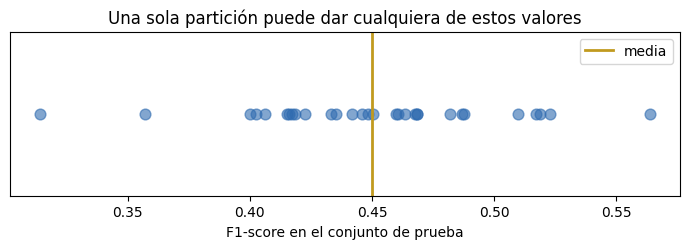

In [3]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
f1s = []
for s in range(30):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=s)
    f1s.append(f1_score(yb, modelo.fit(Xa, ya).predict(Xb)))
f1s = np.array(f1s)
print(f"F1 en prueba con 30 particiones distintas: mín {f1s.min():.3f} · máx {f1s.max():.3f} · media {f1s.mean():.3f}")

plt.figure(figsize=(7, 2.6))
plt.scatter(f1s, np.zeros_like(f1s), s=60, alpha=.6, color="#2F6BB0")
plt.axvline(f1s.mean(), color="#C19A1F", lw=2, label="media")
plt.yticks([]); plt.xlabel("F1-score en el conjunto de prueba"); plt.legend(); plt.title("Una sola partición puede dar cualquiera de estos valores")
plt.tight_layout(); plt.show()

### B.2 · K-fold y k-fold estratificado
Con k-fold, cada cliente se usa una vez para probar y k − 1 veces para entrenar. Comparamos k-fold normal y estratificado con k = 5.

In [4]:
for nombre, cv in [("K-fold", KFold(5, shuffle=True, random_state=3)), ("K-fold estratificado", StratifiedKFold(5, shuffle=True, random_state=3))]:
    sc = cross_val_score(modelo, X, y, cv=cv, scoring="f1")
    prop = [y.iloc[te].mean() for _, te in cv.split(X, y)]
    print(f"{nombre:22s} F1 por fold: {np.round(sc, 3)} → media {sc.mean():.3f} ± {sc.std():.3f}")
    print(f"{'':22s} % de cancelación en cada fold de prueba: {[f'{p:.1%}' for p in prop]}\n")

K-fold                 F1 por fold: [0.51  0.446 0.51  0.392 0.425] → media 0.456 ± 0.047
                       % de cancelación en cada fold de prueba: ['16.3%', '17.3%', '17.0%', '17.3%', '16.0%']

K-fold estratificado   F1 por fold: [0.446 0.408 0.438 0.466 0.497] → media 0.451 ± 0.030
                       % de cancelación en cada fold de prueba: ['16.8%', '16.8%', '16.8%', '16.8%', '16.7%']



**Observa:** el estratificado mantiene la proporción de cancelaciones prácticamente idéntica en cada fold. El promedio de k-fold es una estimación más estable que cualquier partición individual de B.1: **no mejora el modelo, mejora la confianza en la medición.**

## Parte C · Métricas de regresión: costo del siniestro

Ahora estimamos un número: el costo del último siniestro (en miles de pesos). Entrenamos una regresión lineal y calculamos las métricas del Tema 2 **sobre el conjunto de prueba**.

In [5]:
X = df[['edad','antiguedad_meses','prima_mensual','num_reclamaciones','satisfaccion','canal_digital']]
yr = df["costo_siniestro_miles"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, yr, test_size=0.2, random_state=1)
reg = LinearRegression().fit(Xr_tr, yr_tr)
pred = reg.predict(Xr_te)

n_, p_ = len(yr_te), X.shape[1]
sse = np.sum((yr_te - pred) ** 2)
mse = mean_squared_error(yr_te, pred)
r2 = r2_score(yr_te, pred)
tabla = pd.DataFrame({
    "Métrica": ["SSE", "MSE", "RMSE", "R²", "R² ajustado", "MAE", "MAPE"],
    "Valor": [sse, mse, np.sqrt(mse), r2, 1 - (1 - r2) * (n_ - 1) / (n_ - p_ - 1),
              mean_absolute_error(yr_te, pred), mean_absolute_percentage_error(yr_te, pred)],
    "Cómo se lee": ["Crece con n; no compara conjuntos de distinto tamaño", "Unidades al cuadrado (miles²)",
                    "Error típico, en miles de pesos", "Proporción de variación explicada",
                    "Penaliza el número de variables", "Error medio absoluto, en miles de pesos",
                    "Fracción: 0.10 = 10 %"]})
tabla.style.format({"Valor": "{:.3f}"}).hide(axis="index")

Métrica,Valor,Cómo se lee
SSE,5538.721,Crece con n; no compara conjuntos de distinto tamaño
MSE,9.231,Unidades al cuadrado (miles²)
RMSE,3.038,"Error típico, en miles de pesos"
R²,0.688,Proporción de variación explicada
R² ajustado,0.685,Penaliza el número de variables
MAE,2.414,"Error medio absoluto, en miles de pesos"
MAPE,0.132,Fracción: 0.10 = 10 %


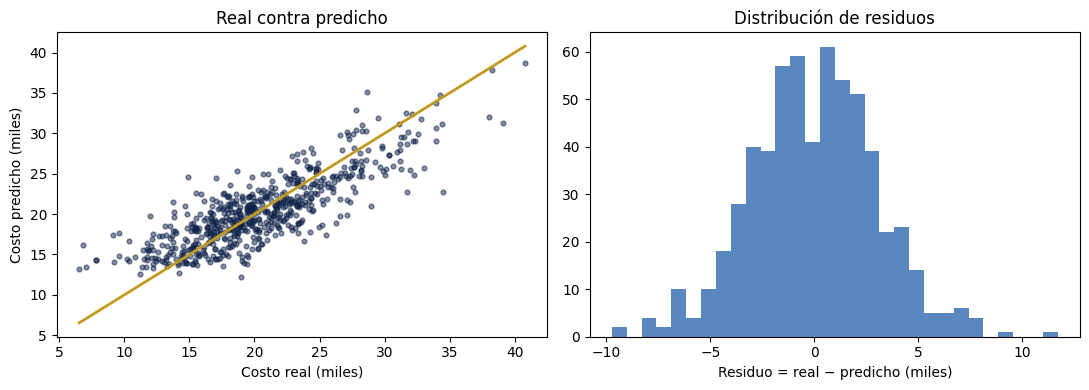

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yr_te, pred, s=12, alpha=.5, color="#0E2148")
lim = [yr_te.min(), yr_te.max()]; ax[0].plot(lim, lim, color="#C19A1F", lw=2)
ax[0].set_xlabel("Costo real (miles)"); ax[0].set_ylabel("Costo predicho (miles)"); ax[0].set_title("Real contra predicho")
ax[1].hist(yr_te - pred, bins=30, color="#2F6BB0", alpha=.8)
ax[1].set_xlabel("Residuo = real − predicho (miles)"); ax[1].set_title("Distribución de residuos")
plt.tight_layout(); plt.show()

### C.2 · ¿Qué pasa con un valor atípico?
Simulamos que en la muestra de prueba aparecen **5 siniestros catastróficos** que el modelo no podía anticipar. ¿Qué métrica se mueve más?

In [7]:
yr_te_out = yr_te.copy()
idx = yr_te_out.sample(5, random_state=0).index
yr_te_out.loc[idx] = yr_te_out.loc[idx] + 250   # +250 mil pesos

for nombre, real in [("Sin atípicos", yr_te), ("Con 5 atípicos", yr_te_out)]:
    print(f"{nombre:15s} RMSE = {np.sqrt(mean_squared_error(real, pred)):6.2f} · MAE = {mean_absolute_error(real, pred):5.2f}")

Sin atípicos    RMSE =   3.04 · MAE =  2.41
Con 5 atípicos  RMSE =  23.14 · MAE =  4.48


**Observa:** 5 casos de 600 disparan el RMSE, mientras que el MAE se mueve mucho menos. Si a la dirección le preocupan los siniestros grandes, el RMSE los refleja; si se quiere un error «típico» robusto a atípicos, el MAE es mejor opción.

## Parte D · Métricas de clasificación: ¿quién va a cancelar?

### D.1 · La trampa de la exactitud
Antes de entrenar, construimos el modelo más tonto posible: **decir siempre que nadie cancela.**

In [8]:
tonto = np.zeros_like(y_test)
print(f"Exactitud del modelo «nadie cancela»: {accuracy_score(y_test, tonto):.1%}")
print(f"Cancelaciones detectadas (sensibilidad): {recall_score(y_test, tonto, zero_division=0):.1%}")

Exactitud del modelo «nadie cancela»: 83.2%
Cancelaciones detectadas (sensibilidad): 0.0%


Una exactitud superior al 80 % sin detectar a un solo cliente. Por eso, con clases desbalanceadas, necesitamos otras métricas.

### D.2 · Regresión logística: matriz de confusión y métricas

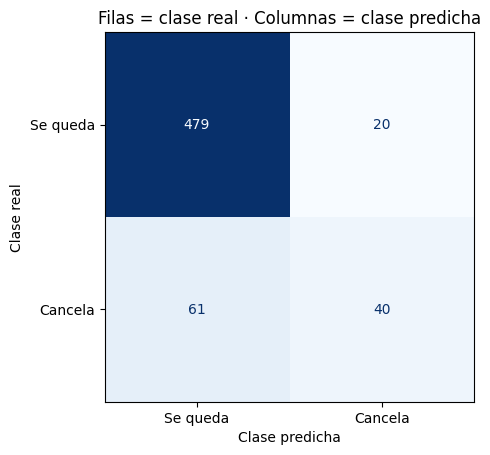

,Umbral 0.5
Exactitud,86.5%
Precisión,66.7%
Sensibilidad,39.6%
Especificidad,96.0%
F1,49.7%


In [9]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]
pred_c = (proba >= 0.5).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_c), display_labels=["Se queda", "Cancela"]).plot(cmap="Blues", colorbar=False)
plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.title("Filas = clase real · Columnas = clase predicha"); plt.show()

def metricas(y_true, y_pred):
    return {"Exactitud": accuracy_score(y_true, y_pred), "Precisión": precision_score(y_true, y_pred, zero_division=0),
            "Sensibilidad": recall_score(y_true, y_pred), "Especificidad": recall_score(y_true, y_pred, pos_label=0),
            "F1": f1_score(y_true, y_pred)}
pd.Series(metricas(y_test, pred_c)).to_frame("Umbral 0.5").style.format("{:.1%}")

**Observa:** la exactitud es alta, pero la **sensibilidad** dice qué fracción de los clientes que realmente se van estamos detectando. Con el umbral por defecto (0.5), se nos escapan muchos.

### D.3 · Curva ROC y AUC

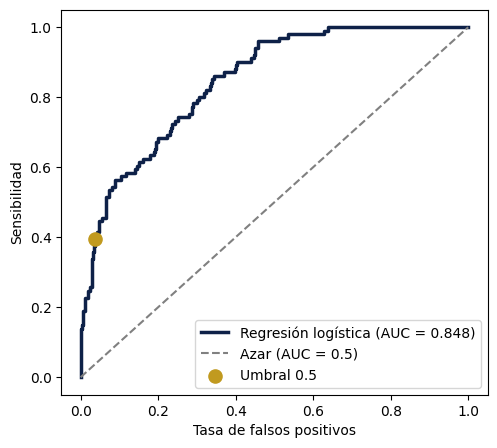

In [10]:
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color="#0E2148", lw=2.5, label=f"Regresión logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
i = np.argmin(np.abs(thr - 0.5)); plt.scatter(fpr[i], tpr[i], s=90, color="#C19A1F", zorder=3, label="Umbral 0.5")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Sensibilidad"); plt.legend(loc="lower right"); plt.show()

### D.4 · El umbral lo decide el negocio
Supongamos estos costos para la aseguradora:

* **Falso negativo:** un cliente que cancela y no detectamos → perdemos **12,000 pesos** de margen.
* **Falso positivo:** ofrecemos un descuento de retención a quien no se iba a ir → cuesta **3,000 pesos**.

Calculamos el costo total para cada umbral y buscamos el mínimo.

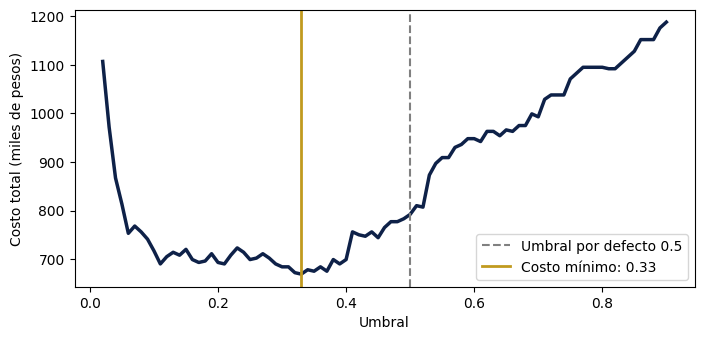

Costo con umbral 0.5: 792,000 · con umbral 0.33: 669,000


,Umbral 0.5,Umbral 0.33
Exactitud,86.5%,84.8%
Precisión,66.7%,54.8%
Sensibilidad,39.6%,56.4%
Especificidad,96.0%,90.6%
F1,49.7%,55.6%


In [11]:
COSTO_FN, COSTO_FP = 12_000, 3_000

umbrales = np.arange(0.02, 0.91, 0.01)
costos = []
for t in umbrales:
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= t).astype(int)).ravel()
    costos.append(fn * COSTO_FN + fp * COSTO_FP)
costos = np.array(costos)
t_opt = umbrales[costos.argmin()]

plt.figure(figsize=(8, 3.6))
plt.plot(umbrales, costos / 1e3, color="#0E2148", lw=2.5)
plt.axvline(0.5, color="gray", ls="--", label="Umbral por defecto 0.5")
plt.axvline(t_opt, color="#C19A1F", lw=2, label=f"Costo mínimo: {t_opt:.2f}")
plt.xlabel("Umbral"); plt.ylabel("Costo total (miles de pesos)"); plt.legend(); plt.show()

comp = pd.DataFrame({"Umbral 0.5": metricas(y_test, (proba >= 0.5).astype(int)),
                     f"Umbral {t_opt:.2f}": metricas(y_test, (proba >= t_opt).astype(int))})
print(f"Costo con umbral 0.5: {costos[np.argmin(np.abs(umbrales-0.5))]:,.0f} · con umbral {t_opt:.2f}: {costos.min():,.0f}")
comp.style.format("{:.1%}")

**Observa:** el umbral que minimiza el costo es más bajo que 0.5. La exactitud baja, pero detectamos muchos más clientes en riesgo y **el costo total cae**. La métrica correcta no la elige el analista: la elige el costo del error.

## Retos

### Reto 1 · ¿Cuánto cambia el resultado?
En la celda de la **Parte A**, cambia `random_state=1` por otros valores (por ejemplo 7, 21 y 99). Anota la exactitud en prueba del árbol. ¿Cuánto varía? ¿Por qué esto justifica usar k-fold?

### Reto 2 · La trampa de R²
La celda siguiente entrena el modelo de costo de siniestros con una muestra pequeña (80 clientes) y luego le agrega 10 variables de **ruido puro**. Compara R² y R² ajustado *en entrenamiento*, y R² *en prueba*. ¿Cuánto sube cada una? ¿Qué pasa en prueba? ¿Qué le dirías a alguien que celebra que «agregar variables mejoró el modelo»?

In [12]:
g = np.random.default_rng(5)
Xs, ys = Xr_tr.iloc[:80], yr_tr.iloc[:80]          # muestra pequeña de entrenamiento
cols = [f"ruido_{i}" for i in range(10)]
Xs_r = pd.concat([Xs, pd.DataFrame(g.normal(size=(80, 10)), columns=cols, index=Xs.index)], axis=1)
Xte_r = pd.concat([Xr_te, pd.DataFrame(g.normal(size=(len(Xr_te), 10)), columns=cols, index=Xr_te.index)], axis=1)

for nombre, A, B in [("6 variables reales", Xs, Xr_te), ("6 reales + 10 de ruido", Xs_r, Xte_r)]:
    m = LinearRegression().fit(A, ys)
    r2 = r2_score(ys, m.predict(A)); n_, p_ = A.shape
    r2a = 1 - (1 - r2) * (n_ - 1) / (n_ - p_ - 1)
    print(f"{nombre:25s} R² train = {r2:.3f} · R² ajustado train = {r2a:.3f} · R² prueba = {r2_score(yr_te, m.predict(B)):.3f}")

6 variables reales        R² train = 0.690 · R² ajustado train = 0.665 · R² prueba = 0.673
6 reales + 10 de ruido    R² train = 0.775 · R² ajustado train = 0.717 · R² prueba = 0.592


### Reto 3 · Cambian los costos
La dirección decide que el descuento de retención es más caro: **COSTO_FP = 8,000**. Cambia el valor en la celda de la Parte D.4 y vuelve a ejecutarla.
¿Hacia dónde se mueve el umbral óptimo? ¿Qué métrica mejora y cuál empeora?

<details><summary><b>Pistas para revisar tus respuestas</b></summary>

* **Reto 1:** la exactitud en prueba cambia con la semilla; una sola partición no basta para reportar con confianza.
* **Reto 2:** R² en entrenamiento sube bastante con el ruido; R² ajustado sube menos porque penaliza las variables, pero con muestras pequeñas no siempre basta. El juez definitivo es la prueba: ahí el modelo con ruido empeora.
* **Reto 3:** si las alertas falsas cuestan más, el umbral óptimo sube: aumenta la precisión y baja la sensibilidad.
</details>

## Anexo · Ejemplo 5 del manual, corregido

El manual entrena y evalúa la regresión logística con **los mismos datos** (importa `train_test_split`, pero no lo usa). Esta es la versión con partición estratificada. Todas las demás salidas numéricas del manual se reproducen sin cambios.

In [13]:
from sklearn.datasets import make_blobs
Xm, ym = make_blobs(n_samples=1000, n_features=2, centers=2, cluster_std=[2.5, 1.5], random_state=20)

# Versión del manual: entrena y evalúa con los mismos datos
c_manual = LogisticRegression(random_state=123).fit(Xm, ym)
print("Manual (sobre entrenamiento):", confusion_matrix(ym, c_manual.predict(Xm)).tolist(),
      f"AUC = {roc_auc_score(ym, c_manual.predict_proba(Xm)[:, 1]):.5f}")

# Versión corregida: 80/20 estratificado
Xa, Xb, ya, yb = train_test_split(Xm, ym, test_size=0.2, stratify=ym, random_state=42)
c = LogisticRegression(random_state=123).fit(Xa, ya)
pb = c.predict(Xb)
print("Corregido (sobre prueba):    ", confusion_matrix(yb, pb).tolist(),
      f"AUC = {roc_auc_score(yb, c.predict_proba(Xb)[:, 1]):.5f}")
pd.Series(metricas(yb, pb)).to_frame("Prueba").style.format("{:.1%}")

Manual (sobre entrenamiento): [[468, 32], [16, 484]] AUC = 0.98722
Corregido (sobre prueba):     [[96, 4], [2, 98]] AUC = 0.98810


,Prueba
Exactitud,97.0%
Precisión,96.1%
Sensibilidad,98.0%
Especificidad,96.0%
F1,97.0%


En este ejemplo los números casi no cambian porque las dos clases están muy separadas. En datos reales, como los de la aseguradora, la diferencia entre entrenamiento y prueba puede ser grande (recuerda la Parte A). **El procedimiento correcto es siempre evaluar con datos que el modelo no vio.**

---
### Resumen
1. Se evalúa con datos no vistos; el conjunto de prueba se aparta al inicio.
2. K-fold da una estimación más estable; estratifica si las clases están desbalanceadas.
3. RMSE castiga los errores grandes, MAE resiste atípicos y R² ajustado compara modelos con distinto número de variables.
4. Con clases desbalanceadas, la exactitud engaña: el umbral y la métrica se eligen por el costo del error.